# 01 · CNN paso a paso sobre Fashion-MNIST

> Tutorial didactico. De los datos a un modelo entrenado, con una
> explicacion por paso. Al final el modelo queda guardado y las apps
> de `app/` lo pueden consumir sin duplicar codigo.

## Objetivo

Entender **que hace** una CNN simple sobre un problema real, celda a celda.
No es un recorrido completo de deep learning: es el minimo imprescindible
para que el flujo tenga sentido.

## Prerequisito

Haber instalado el extra:

```bash
uv sync --extra reconocimiento-imagenes --extra dev
```

## ¿Que es Fashion-MNIST?

- **70 000 imagenes** de prendas de ropa (60 000 train, 10 000 test).
- **28x28 pixeles**, en escala de grises.
- **10 clases**: camiseta, pantalon, sueter, vestido, abrigo, sandalia, camisa, zapatilla, bolso, bota.

Es el equivalente moderno de MNIST (digitos). Lo usamos cuando queremos
un problema **real pero chico**: entrena en CPU en pocos minutos y tiene
clases con solapamientos (camisa vs. camiseta, zapatilla vs. sandalia)
que fuerzan al modelo a aprender rasgos y no solo texturas.

La licencia es MIT y el dataset se descarga automatico con `torchvision`.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

print("torch:", torch.__version__)
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

torch: 2.14.1
device: cpu


## Paso 1 — Descargar los datos

`torchvision.datasets.FashionMNIST` descarga el dataset automatico la
primera vez (~30 MB). Dos transformaciones encadenadas:

- `ToTensor()`: convierte cada imagen (enteros 0-255) a un tensor flotante (0.0-1.0).
- `Normalize(media, desviacion)`: resta la media y divide por la desviacion. Los numeros vienen de calcular estadisticas sobre el train de Fashion-MNIST. Normalizar ayuda al optimizador a converger.

In [2]:
TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

train_ds = datasets.FashionMNIST(root="../data", train=True, download=True, transform=TRANSFORM)
test_ds = datasets.FashionMNIST(root="../data", train=False, download=True, transform=TRANSFORM)

CLASES = [
    "camiseta", "pantalon", "sueter", "vestido", "abrigo",
    "sandalia", "camisa", "zapatilla", "bolso", "bota",
]

print(f"train: {len(train_ds)} imagenes")
print(f"test:  {len(test_ds)} imagenes")
img0, y0 = train_ds[0]
print(f"ejemplo: tensor shape = {tuple(img0.shape)} | etiqueta = {y0} ({CLASES[y0]})")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<02:07, 207kB/s]

  0%|          | 65.5k/26.4M [00:00<02:12, 199kB/s]

  0%|          | 98.3k/26.4M [00:00<02:13, 197kB/s]

  1%|          | 229k/26.4M [00:00<01:01, 429kB/s] 

...

 90%|█████████ | 4.00M/4.42M [00:02<00:00, 3.40MB/s]

100%|██████████| 4.42M/4.42M [00:02<00:00, 1.97MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 10.1MB/s]

train: 60000 imagenes
test:  10000 imagenes
ejemplo: tensor shape = (1, 28, 28) | etiqueta = 9 (bota)


## Paso 2 — Mirar las imagenes

Nunca entrenamos sin haber visto el dataset. Mostramos 9 imagenes al azar
con su etiqueta. Si una te confunde a ti, al modelo le va a costar
distinguirla tambien.

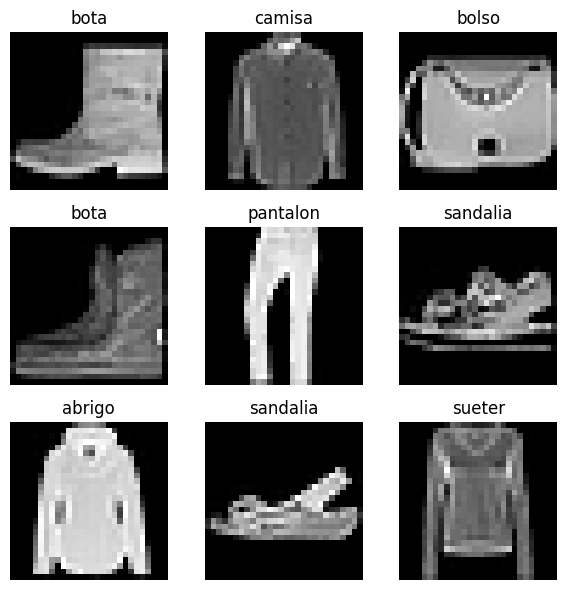

In [3]:
torch.manual_seed(42)
indices = torch.randint(0, len(train_ds), (9,))

fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for ax, idx in zip(axes.flatten(), indices):
    img, etiqueta = train_ds[int(idx)]
    ax.imshow(img.squeeze().numpy(), cmap="gray")
    ax.set_title(CLASES[etiqueta])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Paso 3 — Construir la CNN

Una CNN tiene tres ideas:

1. **Convolucion** (`Conv2d`): aprende filtros que detectan patrones locales (bordes, curvas, texturas). Cada capa produce varios "mapas de activacion".
2. **Pooling** (`MaxPool2d`): reduce el tamano espacial (de 28x28 a 14x14, luego a 7x7). Hace que las capas siguientes miren regiones mas grandes con menos calculos.
3. **Capas densas** (`Linear`) al final: convierten los mapas en una decision de 10 clases.

Flujo de `SimpleCNN`:

```
entrada: (batch, 1, 28, 28)
   -> Conv2d(1 -> 32, 3x3) + ReLU + MaxPool(2)  -> (batch, 32, 14, 14)
   -> Conv2d(32 -> 64, 3x3) + ReLU + MaxPool(2) -> (batch, 64, 7, 7)
   -> Flatten -> Linear(64*7*7 -> 128) + ReLU + Dropout(0.3)
   -> Linear(128 -> 10)
salida: logits de 10 clases
```

`Dropout(0.3)` apaga aleatoriamente el 30% de las neuronas en train para evitar sobreajuste. En eval se apaga solo.

In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_clases=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_clases),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

modelo_demo = SimpleCNN()
total_params = sum(p.numel() for p in modelo_demo.parameters())
print(modelo_demo)
print(f"\nparametros entrenables: {total_params:,}")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

parametros entrenables: 421,642


## Paso 4 — Entrenar

Lo que necesitamos:

- **Loss function**: `CrossEntropyLoss` compara los logits con la etiqueta correcta y produce un numero que queremos minimizar.
- **Optimizador**: `Adam` ajusta los pesos de la red usando gradientes.
- **DataLoader**: entrega los datos en lotes de 64, barajados en train y en orden en test.

Cada **epoca** recorre el dataset completo una vez. En cada epoca hay dos fases:

1. **Train**: `modelo.train()`, calculamos perdida y actualizamos pesos.
2. **Eval**: `modelo.eval()` + `torch.no_grad()`, solo medimos accuracy.

In [5]:
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

modelo = SimpleCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters(), lr=LEARNING_RATE)

historial = []
for epoca in range(1, EPOCHS + 1):
    modelo.train()
    train_loss, train_correctos, train_n = 0.0, 0, 0
    for X, y in train_dl:
        X, y = X.to(device), y.to(device)
        logits = modelo(X)
        perdida = loss_fn(logits, y)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        train_loss += perdida.item() * X.size(0)
        train_correctos += (logits.argmax(1) == y).sum().item()
        train_n += X.size(0)

    modelo.eval()
    test_correctos, test_n = 0, 0
    with torch.no_grad():
        for X, y in test_dl:
            X, y = X.to(device), y.to(device)
            logits = modelo(X)
            test_correctos += (logits.argmax(1) == y).sum().item()
            test_n += X.size(0)

    train_acc = train_correctos / train_n
    test_acc = test_correctos / test_n
    historial.append({"epoca": epoca, "train_loss": train_loss/train_n, "train_acc": train_acc, "test_acc": test_acc})
    print(f"epoca {epoca}/{EPOCHS}  train_loss={train_loss/train_n:.4f}  train_acc={train_acc:.4f}  test_acc={test_acc:.4f}")

epoca 1/5  train_loss=0.4720  train_acc=0.8290  test_acc=0.8789


epoca 2/5  train_loss=0.3062  train_acc=0.8898  test_acc=0.8983


epoca 3/5  train_loss=0.2575  train_acc=0.9072  test_acc=0.9036


epoca 4/5  train_loss=0.2286  train_acc=0.9161  test_acc=0.9169


epoca 5/5  train_loss=0.2023  train_acc=0.9252  test_acc=0.9157


## Paso 5 — Evaluar con mas detalle

Accuracy sola es grosera. Una **matriz de confusion** muestra que clases
se confunden entre si: cada fila es la clase real, cada columna la
predicha, cada celda el conteo. Esperaras ver confusiones entre:

- camisa / camiseta / sueter / abrigo (todas prendas de la parte superior),
- sandalia / zapatilla (calzado abierto vs. deportivo).

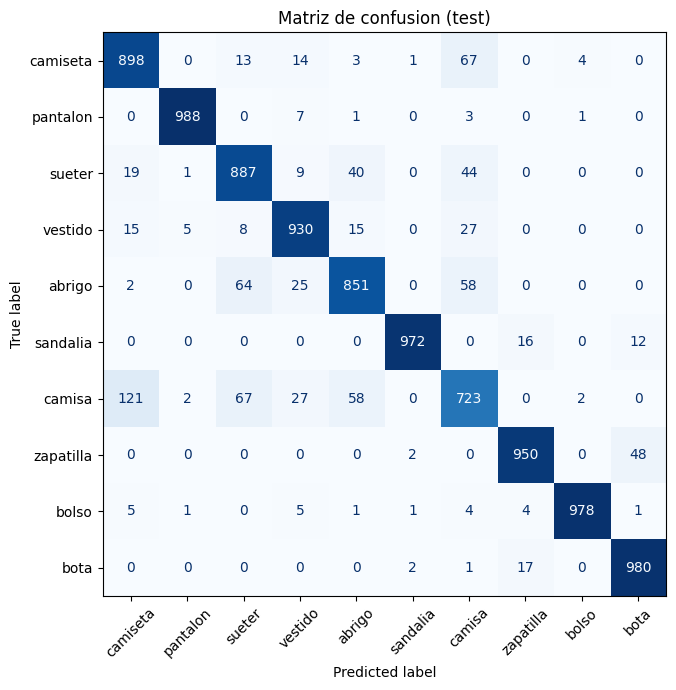

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

modelo.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for X, y in test_dl:
        X = X.to(device)
        preds = modelo(X).argmax(1).cpu().numpy()
        y_true.extend(y.numpy())
        y_pred.extend(preds)

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusion (test)")
plt.tight_layout()
plt.show()

## Paso 6 — Guardar el modelo

Guardamos **solo los pesos** (`state_dict`). La arquitectura vive en
`src/reconocimiento_imagenes/model.py`; al cargar, instanciamos
`SimpleCNN()` y le ponemos los pesos. Separar arquitectura y pesos es
la convencion en PyTorch y evita que un cambio de version rompa modelos
viejos.

In [7]:
from pathlib import Path

MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODELS_DIR / "fashion_cnn.pth"

torch.save(modelo.state_dict(), MODEL_PATH)
print(f"Modelo guardado en {MODEL_PATH.resolve()}")

Modelo guardado en /Users/david.palacio/Documents/data-projects-lab/projects/04-reconocimiento-imagenes/models/fashion_cnn.pth


## ¿Y ahora?

Todo lo que acabas de hacer existe tambien como codigo modular en
`src/reconocimiento_imagenes/`:

| Lo que hiciste aqui | Donde esta en `src/` |
|---|---|
| Descargar y transformar datos | `data.py` |
| Definir `SimpleCNN` | `model.py` |
| Bucle de entrenamiento + eval | `train.py` |
| Cargar `.pth` y predecir sobre una imagen | `predict.py` |
| Constantes (clases, hiperparametros) | `config.py` |

Con eso puedes:

**Reentrenar desde la linea de comandos**, sin notebook:

```bash
uv run python -m reconocimiento_imagenes.train
```

**Lanzar una app Streamlit** (sube una imagen, muestra top-3):

```bash
uv run streamlit run ../app/streamlit_app.py
```

**Exponer el modelo como API con FastAPI**:

```bash
uv run uvicorn app.api_fastapi:app --reload
# luego: http://localhost:8000/docs
```

Las tres rutas (CLI, Streamlit, FastAPI) **importan desde `src/`**. No
hay version "del notebook" y version "de la app" — hay una sola
implementacion y tres formas de invocarla. Eso es lo que buscamos.